# 4376 A line: 200G facula on a continuum-only SSD photosphere

The SSD intensities are replaced by their per-mu continuum level (max over 4370-4384 A), so the quiet star has no line. The facula (200G) is darker than this continuum at every wavelength in the window, so it appears as extra absorption whose Doppler shift follows the facula across the disk.

Run from `actress_highres/actress/` (all paths are relative to it).

In [1]:
import os
import sys
import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import actress.contrasts as contrst

In [2]:
# ===== 4376 A line: 200G facula on a continuum-only (line-free) SSD photosphere =====
# The SSD intensities are replaced by their continuum level, so the quiet star has
# no line. Any line structure in the disk-integrated spectrum then comes only from
# the facula, and its Doppler shift traces the facula as it crosses the disk.

ssd_file = './inputs/limb_files/average_intensities_ssd_driftcorrected.txt'
fac_file = './inputs/limb_files/average_intensities_200G_driftcorrected.txt'
ssd_continuum_file = './inputs/limb_files/average_intensities_ssd_driftcorrected_continuum_4370_4384.txt'

# ----- build the continuum SSD file -----
# Continuum level per mu = max SSD intensity over 4370-4384 A. The simulated window
# itself has no line-free point (its max is ~7% below this at mu=1).
cont_wav_lower = 437.0   # nm, the MURaM files' wavelength column is in nm
cont_wav_higher = 438.4  # nm

ssd = pd.read_csv(ssd_file, sep=r'\s+', comment='#')
intensity_columns = ssd.columns[1:]   # i10 ... i02 -> mu = 1.0 ... 0.2
in_cont_region = (ssd['wavelength'] >= cont_wav_lower) & (ssd['wavelength'] <= cont_wav_higher)
continuum_level = ssd.loc[in_cont_region, intensity_columns].max()

ssd_continuum = ssd.copy()
for col in intensity_columns:
    ssd_continuum[col] = continuum_level[col]   # flat in wavelength, limb darkening kept

print('SSD continuum level per mu (max over 4370-4384 A):')
print(continuum_level.to_string(float_format='{:.6e}'.format))

# Never silently overwrite: if the file already exists it must match what this cell builds.
if os.path.exists(ssd_continuum_file):
    existing = pd.read_csv(ssd_continuum_file, sep=r'\s+', comment='#')
    if not np.allclose(existing.values, ssd_continuum.values, rtol=1e-12, atol=0):
        raise ValueError(f"{ssd_continuum_file} exists but differs from the continuum built here. "
                         "Delete or rename it by hand if it should be replaced.")
    print(f"Using existing {ssd_continuum_file} (identical to the one built here)")
else:
    ssd_continuum.to_csv(ssd_continuum_file, sep=' ', index=False)
    print(f"Wrote {ssd_continuum_file}")

SSD continuum level per mu (max over 4370-4384 A):
i10   3.107200e-05
i09   2.882162e-05
i08   2.657444e-05
i07   2.424981e-05
i06   2.184593e-05
i05   1.935270e-05
i04   1.677131e-05
i03   1.406445e-05
i02   1.120421e-05
Using existing ./inputs/limb_files/average_intensities_ssd_driftcorrected_continuum_4370_4384.txt (identical to the one built here)


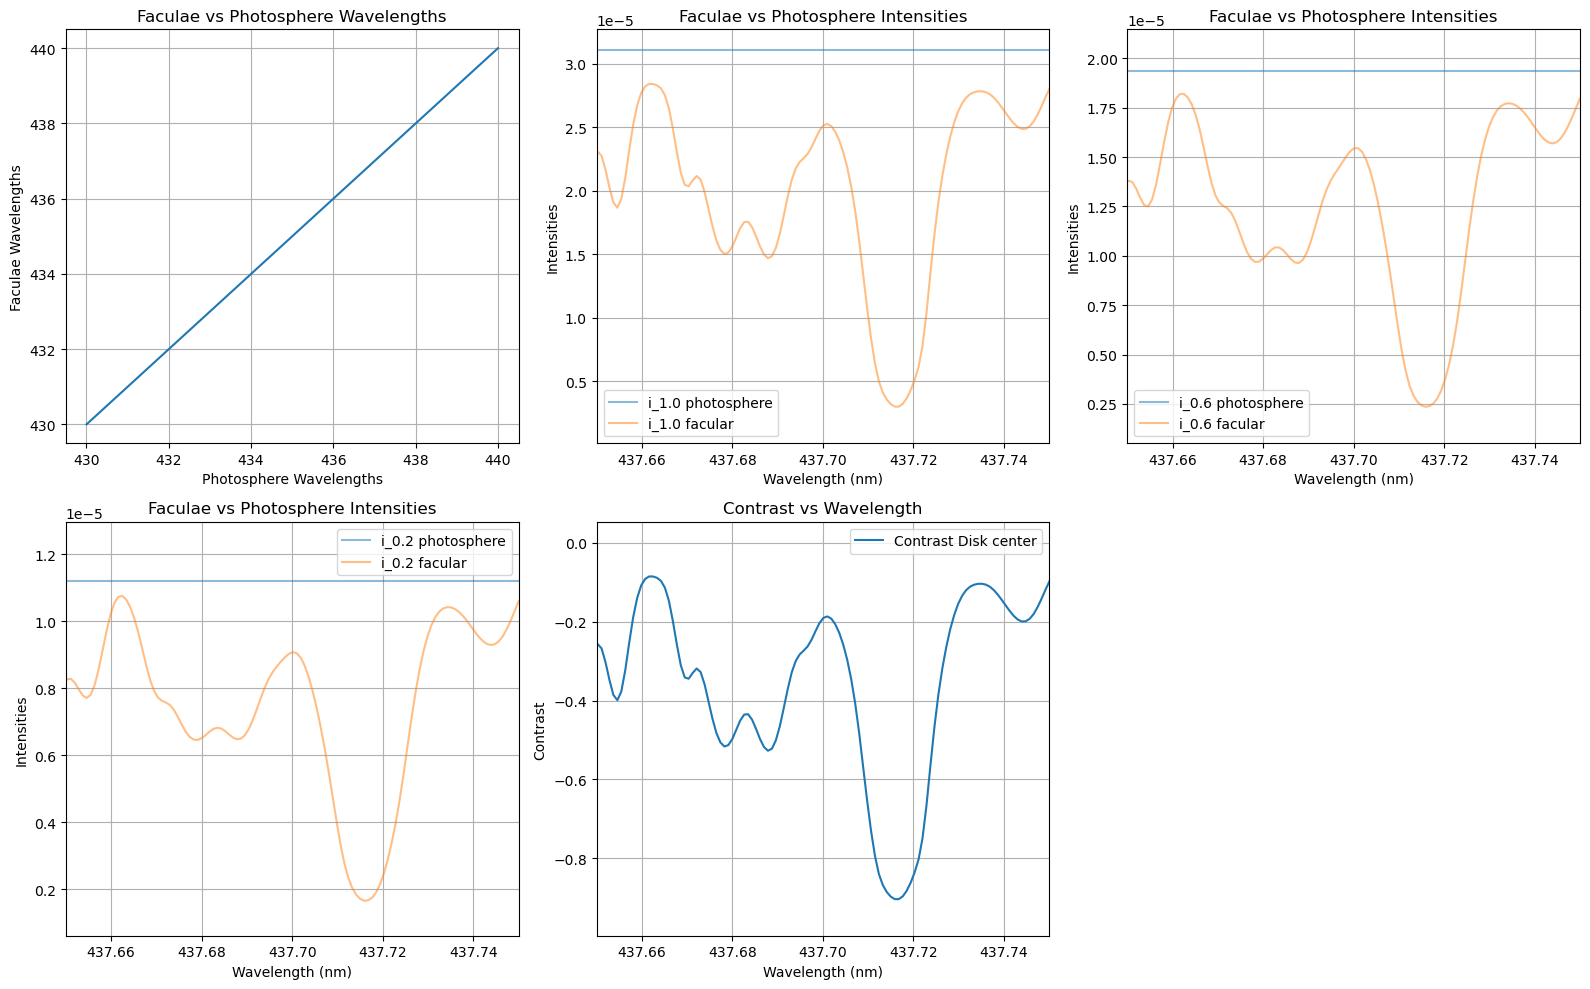

Saved to test_fac_200G_4376.txt
Saved to test_phot_continuum_4376.txt


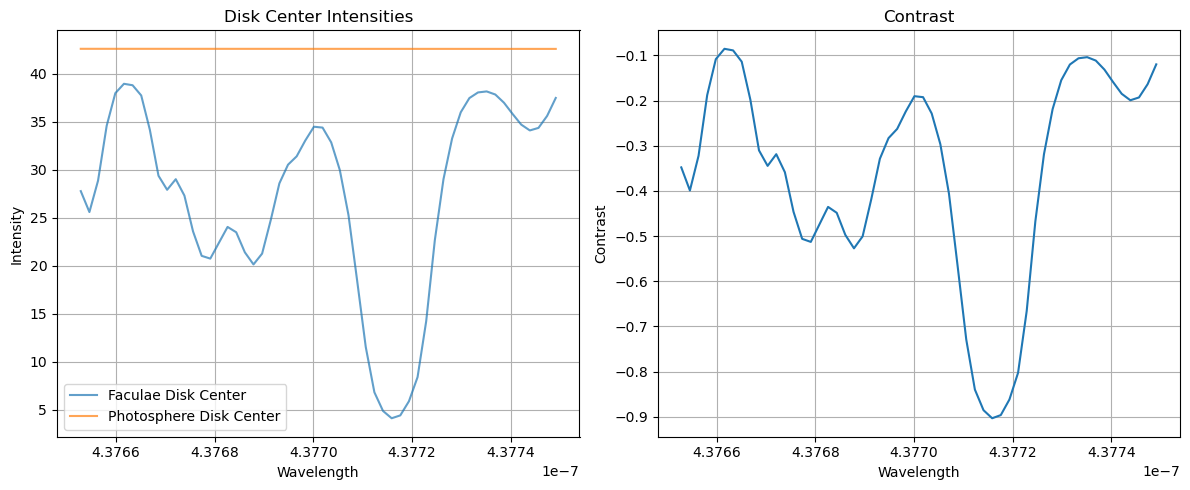

File wavelength steps (A, before rebuilding the grid), 114 steps:
[0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0088
 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088
 0.0087 0.0088 0.0087 0.0088 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087
 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0088
 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088
 0.0087 0.0088 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087
 0.0088 0.0087 0.0088 0.0087 0.0088 0.0088 0.0087 0.0088 0.0087 0.0088
 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0088 0.0087 0.0088 0.0087
 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0088 0.0087 0.0088
 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0088 0.0087
 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0087 0.0088 0.0088
 0.0087 0.0088 0.0087 0.0088]
Input grid steps (A, R = 500000 log grid), 114 steps:
[0.008753   0.00875302 0.00875304 0.00875306 0.00875307 0.00875309
 0

In [4]:
# ----- limb-darkening fits over the 4376 line window -----
hd_ld_file = 'test_phot_continuum_4376.txt'
fac_ld_file = 'test_fac_200G_4376.txt'
ld_law = 'power2'

#True Jean line 1
wav_lower = 4.3765e-7   # m
wav_higher = 4.3775e-7  # m
N_ld = 50   # keeps every 2nd sample (0.0175 A), the grid of the earlier 1_200G_4376.5109_4377.4913 runs

contrst.validate_inputs(fac_file, ssd_continuum_file, wav_lower, wav_higher, graphs=True)

contrst.contrast(fac_file, wav_lower=wav_lower, wav_higher=wav_higher, N=N_ld, ld_law=ld_law, save=fac_ld_file, graphs=False)
contrst.contrast(ssd_continuum_file, wav_lower=wav_lower, wav_higher=wav_higher, N=N_ld, ld_law=ld_law, save=hd_ld_file, graphs=False)

contrst.validate_outputs(fac_ld_file, hd_ld_file, graphs=True)

# ----- wavelength steps: input grid vs output grid -----
# Input: the MURaM grid between the indices contrst.contrast picks for wav_lower..wav_higher.
# Output: the wavelengths contrst.contrast kept. File steps are rounded to 0.0001 A, the precision of
# the file's wavelength column (5 decimals in nm). Grid steps are shown to 1e-8 A: on a log grid each
# step is lambda/R, so they should grow smoothly (~1.75e-8 A per step here) with no jumps.
file_wav_nm = pd.read_csv(ssd_continuum_file, sep=r'\s+', comment='#').values[:, 0]   # nm, rounded as written
file_grid_wav = contrst.wav_nm_to_m(file_wav_nm)                                      # m
input_grid_wav = contrst.wav_nm_to_m(contrst.log_uniform_grid(file_wav_nm, R=500000))  # m, the grid contrast() now uses
indx_low, indx_high = contrst.wav_limits(list(input_grid_wav), wav_lower, wav_higher)
file_steps = np.diff(file_grid_wav[indx_low:indx_high + 1]) * 1e10    # A
input_steps = np.diff(input_grid_wav[indx_low:indx_high + 1]) * 1e10  # A
output_steps = np.diff(np.loadtxt(hd_ld_file)[:, 0]) * 1e10            # A

print(f'File wavelength steps (A, before rebuilding the grid), {len(file_steps)} steps:')
print(np.round(file_steps, 4))
print(f'Input grid steps (A, R = 500000 log grid), {len(input_steps)} steps:')
print(np.round(input_steps, 8))
print(f'Output grid steps (A), {len(output_steps)} steps:')
print(np.round(output_steps, 8))


In [6]:
# ----- simulations -----
def run_disk_simulation(hd_ld_file, fac_ld_file, fac_r, fac_long, fac_lat, v_eq, inc, n_phases, res3d, save):
    """Runs in a separate process so actress loads fresh, as in the multiprocessing cell above."""
    import actress.run_actress_notebook as actr

    params = actr.Transitparams()

    # star parameters
    params.res3d = res3d        # resolution of the 3d healpix grid 2^n
    params.res2d = 100          # Resolution of the resulting 2d simulation box (one side)
    params.v_eq = v_eq          # Equatorial rotational velocity in m/s
    params.inc = inc            # Inclination of the star's rotation axis in degrees
    params.N = n_phases         # Number of phases
    params.mode = 'faconly'
    params.fac_r    = [fac_r]   # degrees
    params.fac_long = [fac_long]
    params.fac_lat  = [fac_lat]
    params.fac_band = False
    params.fac_band_low = [0]
    params.fac_band_high = [0]
    params.ld = 'power2'

    # planet parameters (unused by disk_save, but Transitsim requires them)
    params.rp = 0.1808
    params.b = -0.04
    params.a = 2
    params.T = 20
    params.phi = .5

    print(f"Starting execution for: {save}")
    actr.Transitsim(params).sim_spectrum(hd_ld_file=hd_ld_file, fac_ld_file=fac_ld_file, gif_save=None, lightcurve_save=None, disk_save=save)


fac_r = 15      # deg
fac_long = 0    # deg, 0 shows up at disk center during phase 0
fac_lat = -30    # deg, positive shows up SOUTH of the equator (see cell above)
v_eq = 4000     # m/s
incs = [0,15,35,60,90, 120] # deg, one active and one quiet run per inclination
n_phases = 49   # rotation angles np.linspace(0, 360, n_phases+1)[:-1], as in simulator.rotate_lc
res3d = 6       # healpix nside = 2^6; at 4 the r=15 facula was only ~50 pixels, giving a lumpy line bottom

with open(hd_ld_file, 'r') as f:
    _lines = [line.strip() for line in f if line.strip() and not line.startswith('#')]
    wav_lower_angstroms = float(_lines[0].split()[0]) * 1e10
    wav_higher_angstroms = float(_lines[-1].split()[0]) * 1e10

# res3d is in the names so runs at different resolutions never overwrite each other.
save_prefix = f"1_200G_contSSD_{wav_lower_angstroms:.4f}_{wav_higher_angstroms:.4f}"
cases = {}
for inc in incs:
    cases[inc] = {
        'active': f"{save_prefix}_fac_lat{fac_lat}_long{fac_long}_r{fac_r}_v{v_eq}_i{inc}_N{n_phases}_res{res3d}",
        # A featureless star looks identical at every rotation angle, so one phase is enough for the
        # reference. It still needs its own run per inclination: the Doppler map scales with sin(i).
        'quiet': f"{save_prefix}_fac_lat0_long0_r0_v{v_eq}_i{inc}_N1_res{res3d}",
    }

runs = []
for inc, saves in cases.items():
    runs.append((hd_ld_file, fac_ld_file, fac_r, fac_long, fac_lat, v_eq, inc, n_phases, res3d, saves['active']))
    runs.append((hd_ld_file, fac_ld_file, 0, 0, 0, v_eq, inc, 1, res3d, saves['quiet']))

ctx = mp.get_context('fork')
for run_args in runs:
    process = ctx.Process(target=run_disk_simulation, args=run_args)
    process.start()
    process.join()
    if process.exitcode != 0:
        raise RuntimeError(f"Simulation failed with exit code {process.exitcode}: {run_args[-1]}")
    print(f"Successfully completed: {run_args[-1]}\n")

Starting execution for: 1_200G_contSSD_4376.5109_4377.4913_fac_lat-30_long0_r15_v4000_i0_N49_res6
Facular filling factor 0.033646322378716745
4376.5109 Angstroms
Facular filling factor 0.033646322378716745
4376.5284 Angstroms
Facular filling factor 0.033646322378716745
4376.5459 Angstroms
Facular filling factor 0.033646322378716745
4376.5634 Angstroms
Facular filling factor 0.033646322378716745
4376.5809 Angstroms
Facular filling factor 0.033646322378716745
4376.5984 Angstroms
Facular filling factor 0.033646322378716745
4376.6159 Angstroms
Facular filling factor 0.033646322378716745
4376.6334 Angstroms
Facular filling factor 0.033646322378716745
4376.6509 Angstroms
Facular filling factor 0.033646322378716745
4376.6684 Angstroms
Facular filling factor 0.033646322378716745
4376.6859 Angstroms
Facular filling factor 0.033646322378716745
4376.7034 Angstroms
Facular filling factor 0.033646322378716745
4376.7210 Angstroms
Facular filling factor 0.033646322378716745
4376.7385 Angstroms
Facula

Process ForkProcess-1:
Traceback (most recent call last):
  File "/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/multiprocessing/process.py", line 315, in _bootstrap
    self.run()
  File "/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/rds/general/user/dsy24/ephemeral/ipykernel_3498127/323989549.py", line 31, in run_disk_simulation
    actr.Transitsim(params).sim_spectrum(hd_ld_file=hd_ld_file, fac_ld_file=fac_ld_file, gif_save=None, lightcurve_save=None, disk_save=save)


KeyboardInterrupt: 

  File "/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py", line 199, in sim_spectrum
    self.actress_run(wavelength, wavelength_fac,I0,c1,c2,I0_fac,c1_fac,c2_fac, gif_save=gif_save, lightcurve_save=lightcurve_save, disk_save=disk_save, transit_save=transit_save, transit_disk_save=transit_disk_save) #Dana edit
  File "/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/run_actress_notebook.py", line 106, in actress_run
    disk_fill = sim.getdiscfill(feature='fac', inc = self.inc)
  File "/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.9.egg/actress/simulator.py", line 332, in getdiscfill
    MAT = self.stellarmodel(rot=rot, inc=inc, mode=mode, ldkey=True)
  File "/rds/general/user/dsy24/home/miniforge3/envs/actress_highres1/lib/python3.9/site-packages/actress-1.0-py3.

i = 0: 49 of 49 phases have the facula on the visible disk
  Not plotted (facula entirely on the far side, contrast identically 0): phases []
i = 15: 49 of 49 phases have the facula on the visible disk
  Not plotted (facula entirely on the far side, contrast identically 0): phases []
i = 35: 49 of 49 phases have the facula on the visible disk
  Not plotted (facula entirely on the far side, contrast identically 0): phases []
i = 60: 33 of 49 phases have the facula on the visible disk
  Not plotted (facula entirely on the far side, contrast identically 0): phases [17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32]
i = 90: 29 of 49 phases have the facula on the visible disk
  Not plotted (facula entirely on the far side, contrast identically 0): phases [15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
i = 120: 23 of 49 phases have the facula on the visible disk
  Not plotted (facula entirely on the far side, contrast identically 0): phases [12, 

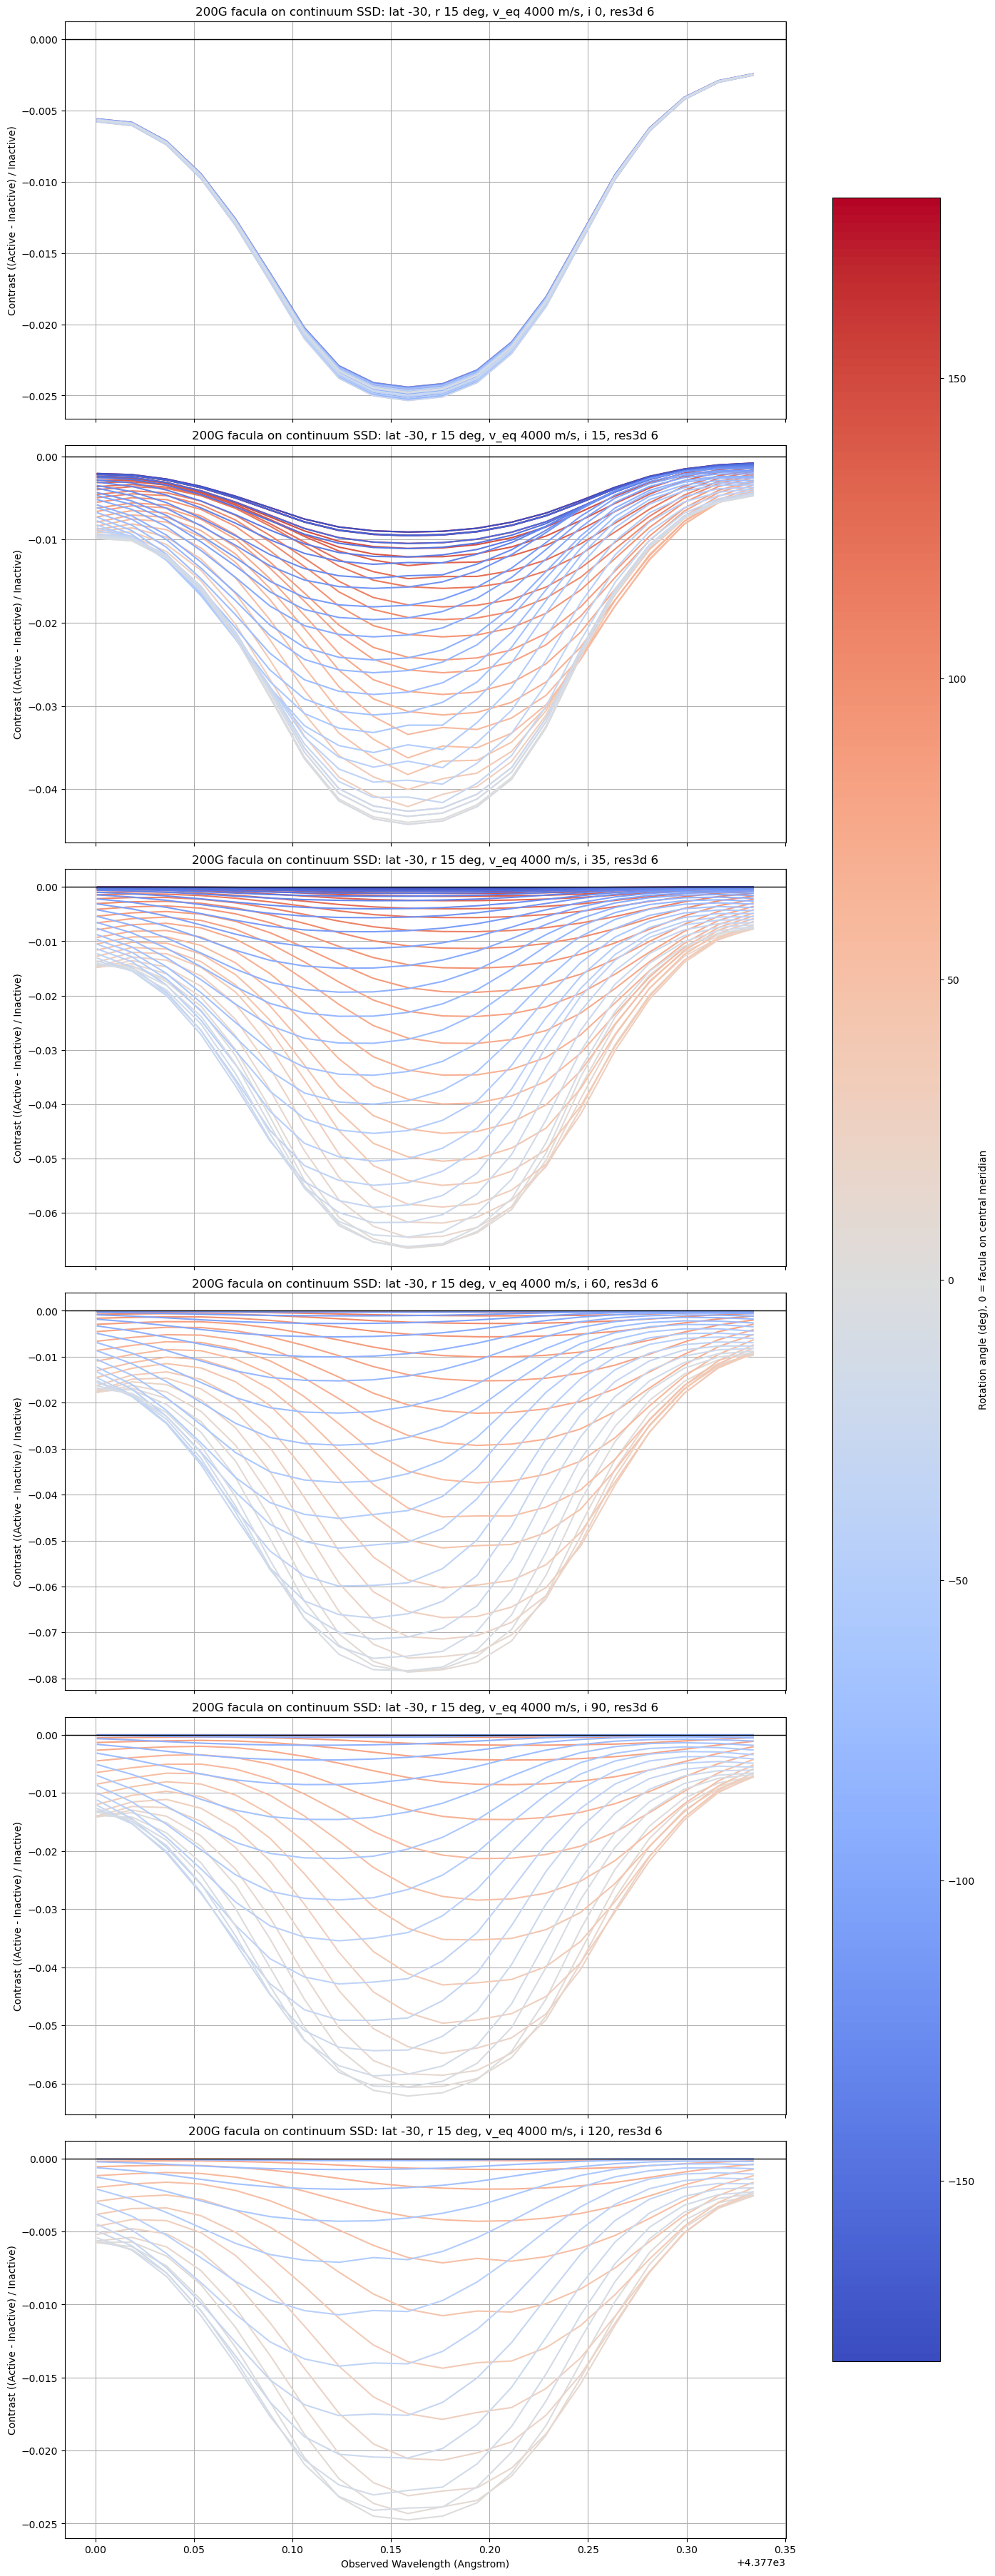

In [80]:
# ----- contrast at each rotation phase -----
sys.path.insert(0, './outputs/full_disks_and_wavelength_shifts')
from disk_utils import process_disk_directory

disk_dir = './outputs/full_disks_and_wavelength_shifts/'
rotation_angles = np.linspace(0, 360, n_phases + 1)[:-1]   # deg, same grid as simulator.rotate_lc

# Plot only this part of the line. Each bin's contrast depends only on input wavelengths
# within the max Doppler shift of it, so the full-window simulation gives identical values here.
plot_wav_lower = 4377.0   # Angstrom
plot_wav_higher = 4377.35  # Angstrom


def contrast_all_phases(save_active, save_quiet):
    """
    Contrast (active - quiet) / quiet at every phase where the facula is visible.

    Returns (bin_centers, contrast_by_phase, hidden_phases). The bins depend on inc, because
    process_disk_directory trims the edges by the maximum Doppler shift, which scales with sin(i).
    """
    bin_centers_quiet, intensity_quiet = process_disk_directory(disk_dir + save_quiet, phase_idx=0)

    contrast_by_phase = {}
    hidden_phases = []
    for phase_idx in range(n_phases):
        bin_centers, intensity_active = process_disk_directory(disk_dir + save_active, phase_idx=phase_idx)
        if not np.array_equal(bin_centers, bin_centers_quiet):
            raise ValueError(f"Wavelength bins differ between {save_active} (phase {phase_idx}) and {save_quiet}")
        contrast = (intensity_active - intensity_quiet) / intensity_quiet
        # Identically zero means no facular pixel is on the visible disk at this phase.
        if np.all(contrast == 0):
            hidden_phases.append(phase_idx)
            continue
        contrast_by_phase[phase_idx] = contrast

    return bin_centers_quiet, contrast_by_phase, hidden_phases


def plot_window_mask(bin_centers):
    """Bins inside plot_wav_lower..plot_wav_higher; raises if the trimmed bins do not cover that range."""
    if bin_centers[0] > plot_wav_lower or bin_centers[-1] < plot_wav_higher:
        raise ValueError(f"Edge-trimmed bins span {bin_centers[0]:.4f}-{bin_centers[-1]:.4f} A "
                         f"and do not cover the plot window {plot_wav_lower}-{plot_wav_higher} A")
    return (bin_centers >= plot_wav_lower) & (bin_centers <= plot_wav_higher)


results = {}
for inc, saves in cases.items():
    bin_centers, contrast_by_phase, hidden_phases = contrast_all_phases(saves['active'], saves['quiet'])
    results[inc] = {
        'bin_centers': bin_centers,
        'in_plot_window': plot_window_mask(bin_centers),
        'contrast_by_phase': contrast_by_phase,
        'hidden_phases': hidden_phases,
    }
    print(f"i = {inc}: {len(contrast_by_phase)} of {n_phases} phases have the facula on the visible disk")
    print(f"  Not plotted (facula entirely on the far side, contrast identically 0): phases {hidden_phases}")

# Signed angle (-180 to 180) so the two limbs get distinct colours; 0 = central meridian.
signed_angles = (rotation_angles + 180) % 360 - 180
cmap = plt.get_cmap('coolwarm')
angle_norm = plt.Normalize(-180, 180)
fig, axes = plt.subplots(len(results), 1, figsize=(14, 6 * len(results)), sharex=True,
                         squeeze=False, constrained_layout=True)
for ax, (inc, res) in zip(axes[:, 0], results.items()):
    window = res['in_plot_window']
    for phase_idx, contrast in res['contrast_by_phase'].items():
        ax.plot(res['bin_centers'][window], contrast[window], color=cmap(angle_norm(signed_angles[phase_idx])), linewidth=1.5)
    ax.axhline(0, color='k', linewidth=1)
    ax.set_ylabel('Contrast ((Active - Inactive) / Inactive)')
    ax.set_title(f'200G facula on continuum SSD: lat {fac_lat}, r {fac_r} deg, v_eq {v_eq} m/s, i {inc}, res3d {res3d}')
    ax.grid(True)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=angle_norm)
fig.colorbar(sm, ax=axes[:, 0].tolist(), label='Rotation angle (deg), 0 = facula on central meridian')
axes[-1, 0].set_xlabel('Observed Wavelength (Angstrom)')
plt.show()

def add_wavelength_offset_axis(ax, rest_wavelengths, c):
    """
    Right-hand axis showing the velocity axis as a wavelength offset from line centre,
    d_lambda = v * lambda_rest / c, used by the line-velocity cells below.

    rest_wavelengths : {inc: rest wavelength (A)}. Each inclination has its own rest wavelength;
    a single axis is exact only if they agree closely, so raise if they differ by more than 1e-5.
    """
    axis_rest = list(rest_wavelengths.values())[0]   # Angstrom
    for inc, rest in rest_wavelengths.items():
        if abs(rest - axis_rest) / axis_rest > 1e-5:
            raise ValueError(f"i = {inc}: rest wavelength {rest:.5f} A differs from {axis_rest:.5f} A "
                             "by too much for a single wavelength-offset axis")

    def velocity_to_wavelength_offset(velocity):
        return velocity * axis_rest / c   # m/s -> A

    def wavelength_offset_to_velocity(wavelength_offset):
        return wavelength_offset * c / axis_rest   # A -> m/s

    ax_wavelength = ax.secondary_yaxis('right', functions=(velocity_to_wavelength_offset, wavelength_offset_to_velocity))
    ax_wavelength.set_ylabel(f'Offset from line centre {axis_rest:.4f} A (A)')
    return ax_wavelength

i = 0: rest wavelength (phase 0 line minimum) 4377.15978 A
phase     t/P   angle  lambda_min (A)   v (m/s)
    0  0.0000    0.00      4377.15978       0.0
    1  0.0204    7.35      4377.15978      -0.1
    2  0.0408   14.69      4377.15977      -1.0
    3  0.0612   22.04      4377.15979       0.2
    4  0.0816   29.39      4377.15979       0.6
    5  0.1020   36.73      4377.15978       0.0
    6  0.1224   44.08      4377.15977      -0.9
    7  0.1429   51.43      4377.15979       0.3
    8  0.1633   58.78      4377.15978      -0.4
    9  0.1837   66.12      4377.15978      -0.5
   10  0.2041   73.47      4377.15977      -0.7
   11  0.2245   80.82      4377.15978      -0.3
   12  0.2449   88.16      4377.15979       0.7
   13  0.2653   95.51      4377.15978      -0.3
   14  0.2857  102.86      4377.15978      -0.4
   15  0.3061  110.20      4377.15978      -0.3
   16  0.3265  117.55      4377.15977      -0.7
   17  0.3469  124.90      4377.15977      -1.0
   18  0.3673  132.24      43

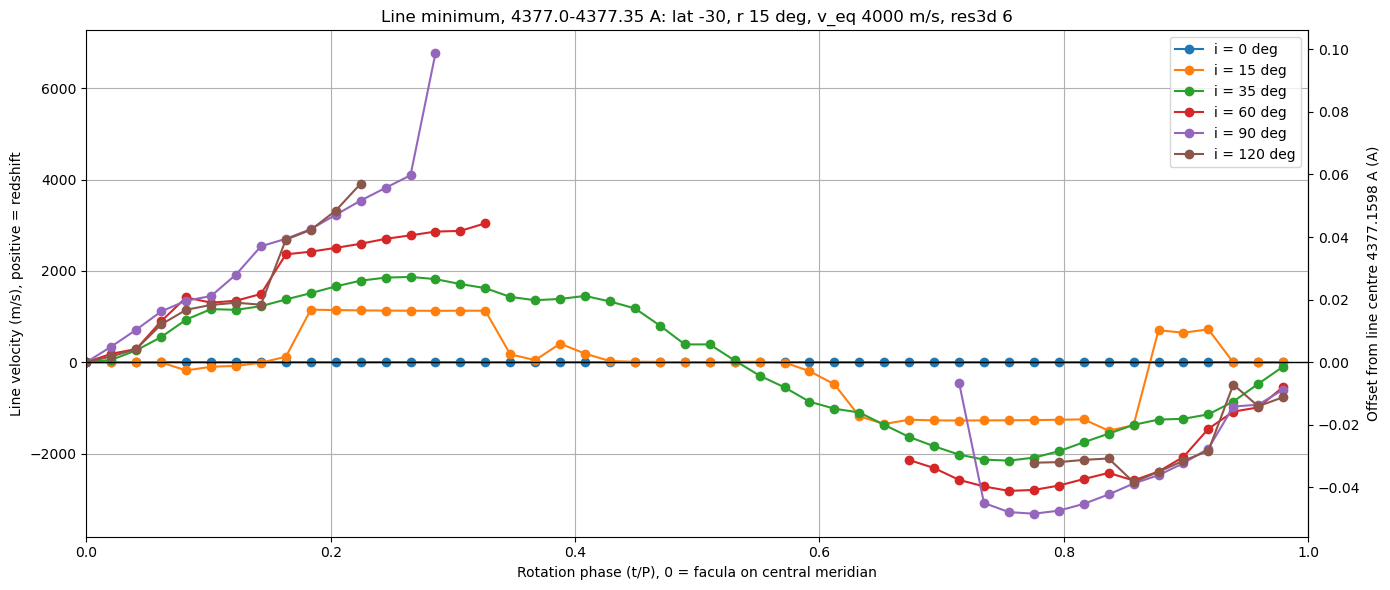

In [81]:
# ----- line velocity per rotation phase -----
# Velocity from the wavelength of the line minimum in the plot window above, refined
# with a parabola through the deepest bin and its two neighbours (bins are 0.0175 A,
# ~1200 m/s, apart, so the raw deepest bin alone is too coarse).
c_sim = 3e8   # m/s, the value simulator.rotate_lc uses to make the shifts, so velocities invert consistently

def line_minimum_wavelength(wavelengths, contrast, label):
    """Wavelength (A) of the contrast minimum from a parabola through the 3 bins around the deepest one."""
    k = np.argmin(contrast)
    if k == 0 or k == len(contrast) - 1:
        raise ValueError(f"{label}: deepest point is at the window edge ({wavelengths[k]:.4f} A), "
                         "so the line minimum is not bracketed inside the window")
    # Fit about the deepest bin, not about ~4377 A, to keep the quadratic well conditioned.
    offsets = wavelengths[k-1:k+2] - wavelengths[k]
    a, b, _ = np.polyfit(offsets, contrast[k-1:k+2], 2)
    if a <= 0:
        raise ValueError(f"{label}: parabola through the deepest bins opens downward (a={a:.3e})")
    return wavelengths[k] - b / (2 * a)

rotation_phase = rotation_angles / 360   # t/P

fig, ax = plt.subplots(figsize=(14, 6))
for inc, res in results.items():
    window = res['in_plot_window']
    window_wavelengths = res['bin_centers'][window]   # Angstrom
    contrast_by_phase = res['contrast_by_phase']

    # Zero velocity: phase 0, where the facula is on the central meridian (closest to disk centre).
    if rotation_angles[0] != 0 or 0 not in contrast_by_phase:
        raise ValueError(f"i = {inc}: phase 0 must be at rotation angle 0 with the facula visible to define the rest wavelength")
    lambda_rest = line_minimum_wavelength(window_wavelengths, contrast_by_phase[0][window], f"i = {inc}, phase 0")

    # NaN for phases with the facula behind the star, so the plotted line breaks there.
    line_velocity = np.full(n_phases, np.nan)   # m/s, positive = redshift (receding)
    line_minimum = np.full(n_phases, np.nan)    # Angstrom
    for phase_idx, contrast in contrast_by_phase.items():
        line_minimum[phase_idx] = line_minimum_wavelength(window_wavelengths, contrast[window], f"i = {inc}, phase {phase_idx}")
        line_velocity[phase_idx] = c_sim * (line_minimum[phase_idx] - lambda_rest) / lambda_rest

    res['lambda_rest'] = lambda_rest
    res['line_minimum'] = line_minimum
    res['line_velocity'] = line_velocity

    print(f"i = {inc}: rest wavelength (phase 0 line minimum) {lambda_rest:.5f} A")
    print(f"{'phase':>5} {'t/P':>7} {'angle':>7} {'lambda_min (A)':>15} {'v (m/s)':>9}")
    for phase_idx in range(n_phases):
        if phase_idx in res['hidden_phases']:
            continue
        print(f"{phase_idx:5d} {rotation_phase[phase_idx]:7.4f} {rotation_angles[phase_idx]:7.2f} "
              f"{line_minimum[phase_idx]:15.5f} {line_velocity[phase_idx]:9.1f}")
    print()

    ax.plot(rotation_phase, line_velocity, marker='o', linewidth=1.5, label=f'i = {inc} deg')

ax.axhline(0, color='k', linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel('Rotation phase (t/P), 0 = facula on central meridian')
ax.set_ylabel('Line velocity (m/s), positive = redshift')
add_wavelength_offset_axis(ax, {inc: res['lambda_rest'] for inc, res in results.items()}, c_sim)
ax.set_title(f'Line minimum, {plot_wav_lower}-{plot_wav_higher} A: lat {fac_lat}, r {fac_r} deg, v_eq {v_eq} m/s, res3d {res3d}')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

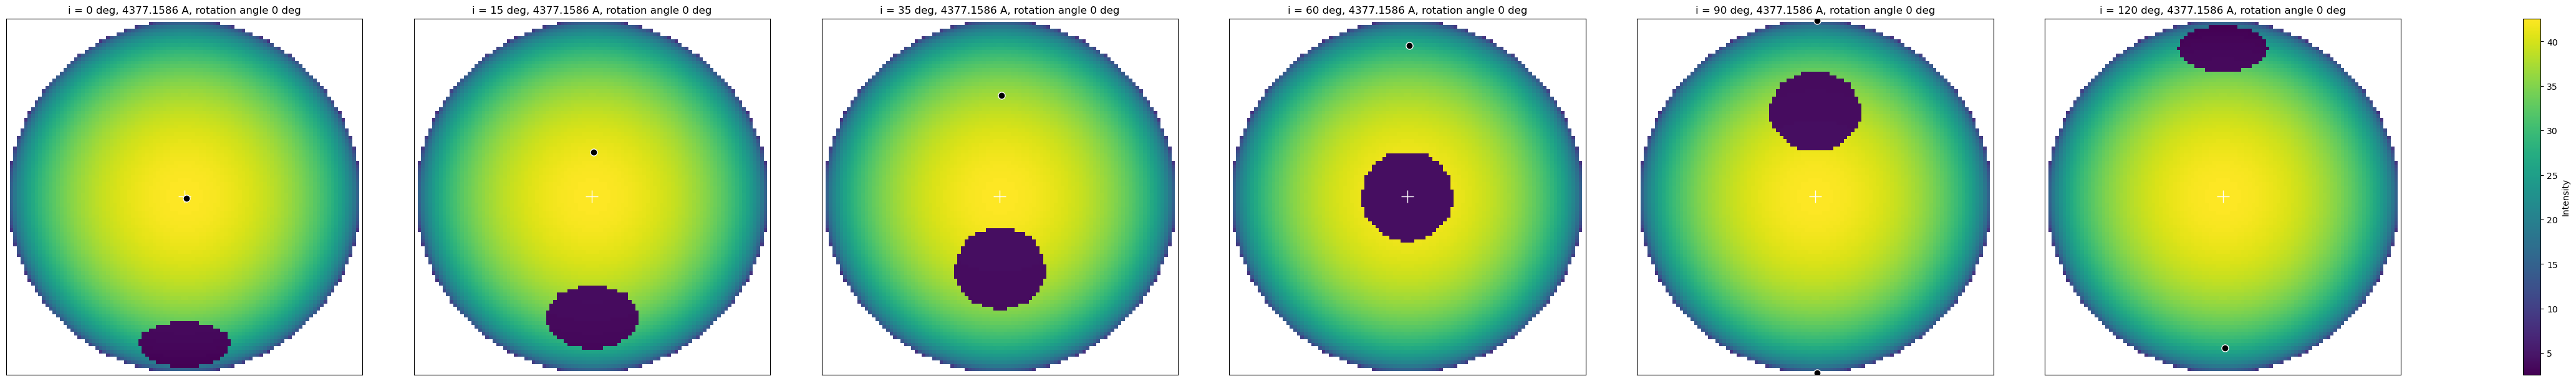

In [82]:
# ----- facula image at rotation angle 0 for each inclination -----
# Disk intensity at the input wavelength nearest the line core, where the facula is darkest
# relative to the continuum photosphere (contrast ~ -0.9 at mu=1), so it stands out clearly.
import glob
import healpy as hp

image_wavelength = 4377.16   # Angstrom, line core
image_phase = 0              # rotation angle 0: facula on the central meridian

def disk_image(save, wavelength, phase_idx):
    """Saved disk intensity map at the input wavelength nearest `wavelength` (A), off-disk set to NaN."""
    files = glob.glob(f"{disk_dir}{save}/disk_inp*.npy")
    if not files:
        raise FileNotFoundError(f"No disk_inp*.npy files in {disk_dir}{save}")
    file_wavelengths = np.array([float(os.path.basename(f)[len('disk_inp'):-len('.npy')]) for f in files])
    nearest = np.argmin(np.abs(file_wavelengths - wavelength))
    disk = np.load(files[nearest], mmap_mode='r')[phase_idx].copy()
    disk[disk == 0] = np.nan   # simulator.rotate_lc sets the off-disk background to 0
    return file_wavelengths[nearest], disk

def visible_pole_pixels(inc, xsize):
    """
    (row, col) image pixels of the rotation pole(s) visible at inclination `inc`.

    Uses the same healpy orthographic projection as simulator.rotate_lc (rot = [0, inc - 90]);
    a pole on the far hemisphere projects to x = NaN. Both poles are on the limb at i = 90.
    Rotation is about the poles, so their position is the same at every rotation phase.
    """
    proj = hp.projector.OrthographicProj(rot=[0, inc - 90], half_sky=True, xsize=xsize)
    poles = []
    for pole_lat in (-90, 90):   # deg, fac_lat convention
        x, y = proj.ang2xy(0, pole_lat, lonlat=True)
        if np.isnan(x):
            continue
        row, col = proj.xy2ij(x, y)
        poles.append((int(row), int(col)))
    return poles

images = {}
for inc, saves in cases.items():
    images[inc] = disk_image(saves['active'], image_wavelength, image_phase)

# Shared colour scale so the two inclinations are directly comparable.
vmin = min(np.nanmin(disk) for _, disk in images.values())
vmax = max(np.nanmax(disk) for _, disk in images.values())

fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 6), squeeze=False, constrained_layout=True)
for ax, (inc, (wavelength, disk)) in zip(axes[0], images.items()):
    im = ax.imshow(disk, cmap='viridis', vmin=vmin, vmax=vmax)
    centre = (disk.shape[1] - 1) / 2
    ax.plot(centre, centre, marker='+', color='w', markersize=15)   # disk centre
    for row, col in visible_pole_pixels(inc, disk.shape[1]):
        ax.plot(col, row, marker='o', color='k', markeredgecolor='w', markersize=8)   # visible pole
    ax.set_title(f'i = {inc} deg, {wavelength:.4f} A, rotation angle {rotation_angles[image_phase]:.0f} deg')
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(im, ax=axes[0].tolist(), label='Intensity')
plt.show()

In [83]:
# ----- rotation animation of the facula image for each inclination -----
# Same images as the cell above, at every rotation phase. Shown inline with to_jshtml,
# so nothing is written to disk.
import matplotlib.animation as animation
from IPython.display import HTML, display

frames_by_inc = {}
for inc, saves in cases.items():
    frames = []
    for phase_idx in range(n_phases):
        frame_wavelength, disk = disk_image(saves['active'], image_wavelength, phase_idx)
        frames.append(disk)
    frames_by_inc[inc] = frames

# One colour scale for every frame and inclination, so brightness changes are real.
vmin = np.inf
vmax = -np.inf
for frames in frames_by_inc.values():
    for disk in frames:
        vmin = min(vmin, np.nanmin(disk))
        vmax = max(vmax, np.nanmax(disk))

fig, axes = plt.subplots(1, len(frames_by_inc), figsize=(7 * len(frames_by_inc), 6), squeeze=False, constrained_layout=True)
ims = {}
for ax, (inc, frames) in zip(axes[0], frames_by_inc.items()):
    ims[inc] = ax.imshow(frames[0], cmap='viridis', vmin=vmin, vmax=vmax)
    centre = (frames[0].shape[1] - 1) / 2
    ax.plot(centre, centre, marker='+', color='w', markersize=15)   # disk centre
    # The poles do not move as the star rotates, so they are drawn once, not per frame.
    for row, col in visible_pole_pixels(inc, frames[0].shape[1]):
        ax.plot(col, row, marker='o', color='k', markeredgecolor='w', markersize=8)   # visible pole
    ax.set_title(f'i = {inc} deg')
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(ims[incs[0]], ax=axes[0].tolist(), label='Intensity')
suptitle = fig.suptitle('')

def update(phase_idx):
    for inc, frames in frames_by_inc.items():
        ims[inc].set_data(frames[phase_idx])
    suptitle.set_text(f'{frame_wavelength:.4f} A, rotation angle {rotation_angles[phase_idx]:.1f} deg '
                      f'(t/P = {rotation_angles[phase_idx] / 360:.3f})')
    return list(ims.values()) + [suptitle]

anim = animation.FuncAnimation(fig, update, frames=n_phases, interval=150)
plt.close(fig)   # otherwise the static first frame is displayed as well
display(HTML(anim.to_jshtml()))

i = 0: rest wavelength (phase 0 line-core centroid) 4377.16195 A
phase     t/P   angle  lambda_c (A)   v (m/s)
    0  0.0000    0.00    4377.16195       0.0
    1  0.0204    7.35    4377.16194      -0.0
    2  0.0408   14.69    4377.16194      -0.5
    3  0.0612   22.04    4377.16195       0.2
    4  0.0816   29.39    4377.16195       0.4
    5  0.1020   36.73    4377.16195       0.1
    6  0.1224   44.08    4377.16194      -0.4
    7  0.1429   51.43    4377.16195       0.2
    8  0.1633   58.78    4377.16194      -0.1
    9  0.1837   66.12    4377.16194      -0.2
   10  0.2041   73.47    4377.16194      -0.4
   11  0.2245   80.82    4377.16195      -0.0
   12  0.2449   88.16    4377.16195       0.4
   13  0.2653   95.51    4377.16194      -0.2
   14  0.2857  102.86    4377.16194      -0.1
   15  0.3061  110.20    4377.16194      -0.1
   16  0.3265  117.55    4377.16194      -0.3
   17  0.3469  124.90    4377.16194      -0.6
   18  0.3673  132.24    4377.16195      -0.0
   19  0.3878  

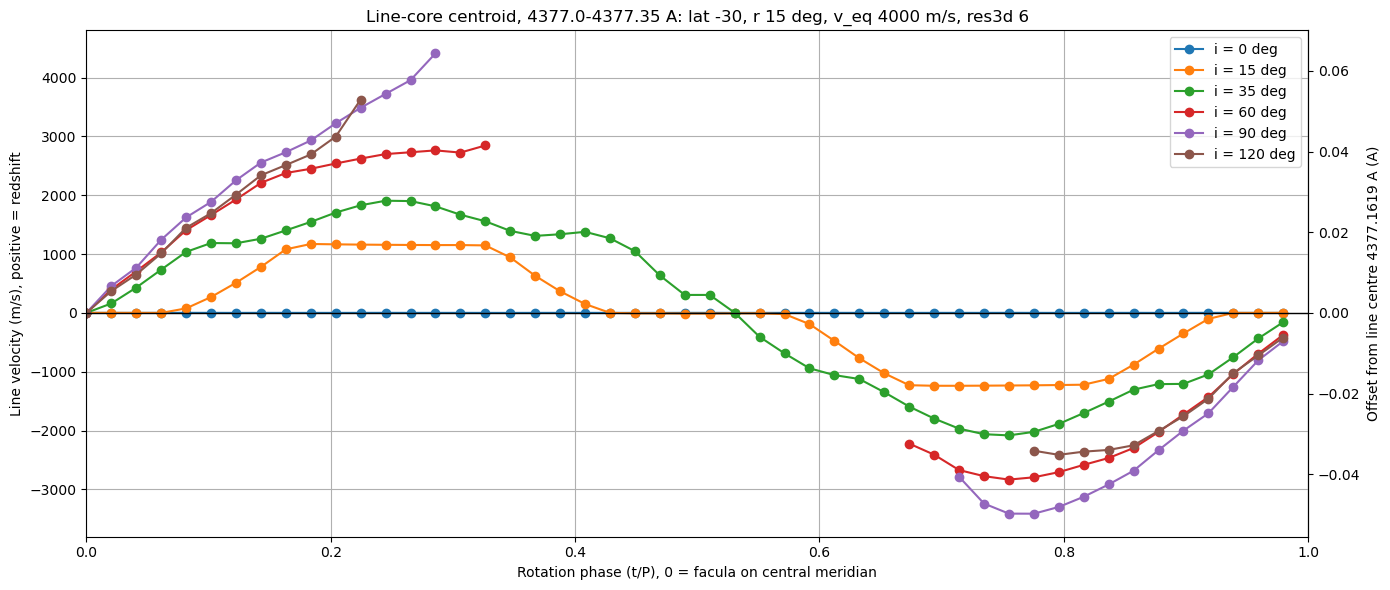

In [84]:
# ----- line velocity per rotation phase: line-core centroid -----
# Alternative to the line-minimum cell above (kept for comparison; results are stored under
# separate keys so both can coexist). Velocity from the centroid of the line core in the plot
# window: the contiguous run of bins around the deepest point that are at least half as deep.
# Each core bin is weighted by how far it lies below that half-depth level, so bins crossing the
# core edge as the line shifts carry ~0 weight and the centroid moves smoothly (plain depth
# weights gave ~900 m/s steps; a 0.3-depth core reaches the blend wing at the window's blue edge).
c_sim = 3e8           # m/s, the value simulator.rotate_lc uses to make the shifts, so velocities invert consistently
core_fraction = 0.5   # line core = contiguous bins with depth >= core_fraction * maximum depth

def line_core_centroid(wavelengths, contrast, label):
    """Wavelength (A) of the line-core centroid; depth = -contrast."""
    depth = -contrast
    k = np.argmax(depth)
    if depth[k] <= 0:
        raise ValueError(f"{label}: no absorption in the window (max depth {depth[k]:.3e})")
    threshold = core_fraction * depth[k]
    lo = k
    while lo > 0 and depth[lo - 1] >= threshold:
        lo -= 1
    hi = k
    while hi < len(depth) - 1 and depth[hi + 1] >= threshold:
        hi += 1
    if lo == 0 or hi == len(depth) - 1:
        raise ValueError(f"{label}: line core ({wavelengths[lo]:.4f}-{wavelengths[hi]:.4f} A) "
                         "reaches the window edge, so it is not fully inside the window")
    core = slice(lo, hi + 1)
    weight = depth[core] - threshold
    return np.sum(wavelengths[core] * weight) / np.sum(weight)

rotation_phase = rotation_angles / 360   # t/P

fig, ax = plt.subplots(figsize=(14, 6))
for inc, res in results.items():
    window = res['in_plot_window']
    window_wavelengths = res['bin_centers'][window]   # Angstrom
    contrast_by_phase = res['contrast_by_phase']

    # Zero velocity: phase 0, where the facula is on the central meridian (closest to disk centre).
    if rotation_angles[0] != 0 or 0 not in contrast_by_phase:
        raise ValueError(f"i = {inc}: phase 0 must be at rotation angle 0 with the facula visible to define the rest wavelength")
    centroid_rest = line_core_centroid(window_wavelengths, contrast_by_phase[0][window], f"i = {inc}, phase 0")

    # NaN for phases with the facula behind the star, so the plotted line breaks there.
    centroid_velocity = np.full(n_phases, np.nan)   # m/s, positive = redshift (receding)
    line_centroid = np.full(n_phases, np.nan)       # Angstrom
    for phase_idx, contrast in contrast_by_phase.items():
        line_centroid[phase_idx] = line_core_centroid(window_wavelengths, contrast[window], f"i = {inc}, phase {phase_idx}")
        centroid_velocity[phase_idx] = c_sim * (line_centroid[phase_idx] - centroid_rest) / centroid_rest

    res['centroid_rest'] = centroid_rest
    res['line_centroid'] = line_centroid
    res['centroid_velocity'] = centroid_velocity

    print(f"i = {inc}: rest wavelength (phase 0 line-core centroid) {centroid_rest:.5f} A")
    print(f"{'phase':>5} {'t/P':>7} {'angle':>7} {'lambda_c (A)':>13} {'v (m/s)':>9}")
    for phase_idx in range(n_phases):
        if phase_idx in res['hidden_phases']:
            continue
        print(f"{phase_idx:5d} {rotation_phase[phase_idx]:7.4f} {rotation_angles[phase_idx]:7.2f} "
              f"{line_centroid[phase_idx]:13.5f} {centroid_velocity[phase_idx]:9.1f}")
    print()

    ax.plot(rotation_phase, centroid_velocity, marker='o', linewidth=1.5, label=f'i = {inc} deg')

ax.axhline(0, color='k', linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel('Rotation phase (t/P), 0 = facula on central meridian')
ax.set_ylabel('Line velocity (m/s), positive = redshift')
add_wavelength_offset_axis(ax, {inc: res['centroid_rest'] for inc, res in results.items()}, c_sim)
ax.set_title(f'Line-core centroid, {plot_wav_lower}-{plot_wav_higher} A: lat {fac_lat}, r {fac_r} deg, v_eq {v_eq} m/s, res3d {res3d}')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

In [3]:
# ----- limb-darkening law comparison: are the bumps in I0 from the fit? -----
# In contrasts.contrast, I0 is not fitted: it is the mu = 1 intensity times the frequency width of
# its wavelength bin (delta_freq); only the shape coefficients come from the fit. If the bumps come
# from the bin widths, I0 is identical for every law and follows delta_freq exactly. The MURaM grid
# steps by 0.0087 A with occasional 0.0088 A steps, so a few bins are ~0.6% wider than the rest.
ld_laws = ['power2', 'quadratic', 'claret']   # the laws Transitsim.ld_law implements
ld_comparison_dir = './ld_law_comparison'
os.makedirs(ld_comparison_dir, exist_ok=True)

ld_fits = {}   # (law, 'phot' or 'fac') -> contrast() output: wavelength (m), I0, coefficients
for law in ld_laws:
    for name, source_file in (('phot', ssd_continuum_file), ('fac', fac_file)):
        save_path = f'{ld_comparison_dir}/{name}_{law}_4376.txt'
        contrst.contrast(source_file, wav_lower=wav_lower, wav_higher=wav_higher, N=N_ld, ld_law=law, save=save_path, graphs=False)
        ld_fits[(law, name)] = np.loadtxt(save_path)

mu_columns = np.array([1, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2])   # mu of the MURaM columns i10 ... i02

def fitted_intensity(fit_row, law, mu):
    """I(mu) from one row of a contrast() output file, through the same contrst.ld the fit used."""
    x = contrst.costheta_to_ster(mu)
    if law == 'claret':
        return contrst.ld(x, fit_row[2], fit_row[3], fit_row[1], law, c=fit_row[4], d=fit_row[5])
    return contrst.ld(x, fit_row[2], fit_row[3], fit_row[1], law)

def binned_input_intensities(source_file, fit):
    """
    MURaM intensities at the fitted wavelengths, scaled exactly as contrast() scales them.

    Returns (intensities (n_wl, 9 mu) in SI x delta_freq, delta_freq (n_wl,) in Hz). delta_freq is
    computed from the wavelength grid with the formula in contrasts.contrast (c = 3e8 there), not
    recovered from I0, so comparing it with I0 is an independent check.
    """
    raw = pd.read_csv(source_file, sep=r'\s+', comment='#').values
    raw_wavelengths = contrst.wav_nm_to_m(raw[:, 0])   # m
    rows = []
    for fit_wavelength in fit[:, 0]:
        rows.append(int(np.argmin(np.abs(raw_wavelengths - fit_wavelength))))
    rows = np.array(rows)
    if not np.allclose(raw_wavelengths[rows], fit[:, 0], rtol=0, atol=1e-16):
        raise ValueError(f"Fitted wavelengths do not match rows of {source_file}")
    delta_freq = (3e8 / raw_wavelengths[rows - 1] - 3e8 / raw_wavelengths[rows + 1]) / 2   # Hz
    return contrst.cgs_to_si(raw[rows, 1:]) * delta_freq[:, None], delta_freq

# ----- 1) I0 across laws, against the bin widths -----
phot_data, delta_freq = binned_input_intensities(ssd_continuum_file, ld_fits[('power2', 'phot')])
fit_wavelengths = ld_fits[('power2', 'phot')][:, 0] * 1e10   # Angstrom

for law in ld_laws:
    for name in ('phot', 'fac'):
        I0_ratio = ld_fits[(law, name)][:, 1] / ld_fits[('power2', name)][:, 1]
        print(f"{name:4s} {law:9s}: max |I0 / I0_power2 - 1| = {np.abs(I0_ratio - 1).max():.2e}")
if not np.allclose(ld_fits[('power2', 'phot')][:, 1], phot_data[:, 0], rtol=1e-12, atol=0):
    raise ValueError("I0 is not the mu = 1 intensity times delta_freq; contrast() has changed")
print(f"phot I0 spread {np.ptp(phot_data[:, 0]) / phot_data[:, 0].mean() * 100:.2f}%, "
      f"delta_freq spread {np.ptp(delta_freq) / delta_freq.mean() * 100:.2f}%")

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, constrained_layout=True)
for law, linestyle in zip(ld_laws, ['-', '--', ':']):
    I0 = ld_fits[(law, 'phot')][:, 1]
    axes[0].plot(fit_wavelengths, I0 / I0.mean(), linestyle=linestyle, linewidth=2, label=f'phot I0, {law}')
    axes[1].plot(fit_wavelengths, (I0 / delta_freq) / (I0 / delta_freq).mean(), linestyle=linestyle, linewidth=2, label=f'phot I0 / delta_freq, {law}')
axes[0].plot(fit_wavelengths, delta_freq / delta_freq.mean(), color='k', linestyle='none', marker='o', markersize=5, label='delta_freq (bin width)')
axes[0].set_ylabel('Normalised to mean')
axes[0].set_title('Continuum SSD I0 for each law vs the frequency width of each bin')
axes[1].set_ylabel('Normalised to mean')
axes[1].set_title('I0 divided by bin width: flat if the bumps are entirely the bin widths')
axes[1].set_xlabel('Wavelength (Angstrom)')
for ax in axes:
    ax.ticklabel_format(axis='x', useOffset=False)
    ax.legend()
    ax.grid(True)
plt.show()

# ----- 2) fit quality of each law at the MURaM mu values -----
max_residual = {}   # (law, name) -> max over wavelengths of |fit - data| / data, per mu
for name, source_file in (('phot', ssd_continuum_file), ('fac', fac_file)):
    for law in ld_laws:
        fit = ld_fits[(law, name)]
        data, _ = binned_input_intensities(source_file, fit)
        model = np.zeros_like(data)
        for k in range(len(fit)):
            model[k] = fitted_intensity(fit[k], law, mu_columns)
        max_residual[(law, name)] = np.max(np.abs(model - data) / data, axis=0)
        print(f"{name:4s} {law:9s}: max |fit - data| / data = {np.max(np.abs(model - data) / data) * 100:.3f}%")

        # Transitsim evaluates these laws all the way to the limb (mu -> 0), below the lowest MURaM
        # mu of 0.2. A negative intensity there is unphysical, so flag every wavelength where it happens.
        mu_limb = np.linspace(0, mu_columns.min(), 101)
        n_negative = 0
        worst_mu = None
        for k in range(len(fit)):
            limb_intensity = fitted_intensity(fit[k], law, mu_limb)
            if np.any(limb_intensity < 0):
                n_negative += 1
                highest_negative_mu = mu_limb[limb_intensity < 0].max()
                if worst_mu is None or highest_negative_mu > worst_mu:
                    worst_mu = highest_negative_mu
        if n_negative > 0:
            print(f"  WARNING: {name} {law} gives NEGATIVE intensity below mu = 0.2 at {n_negative} of {len(fit)} "
                  f"wavelengths (going negative from mu up to {worst_mu:.3f})")

fig, axes = plt.subplots(1, 3, figsize=(20, 6), constrained_layout=True)
for ax, name in zip(axes[:2], ('phot', 'fac')):
    for law in ld_laws:
        ax.plot(mu_columns, max_residual[(law, name)] * 100, marker='o', linewidth=1.5, label=law)
    ax.set_xlabel('mu')
    ax.set_ylabel('Max over wavelengths of |fit - data| / data (%)')
    ax.set_title(f'{name}: limb-darkening fit residuals')
    ax.invert_xaxis()
    ax.legend()
    ax.grid(True)

# ----- 3) facular I(mu) at the line core, including below the lowest MURaM mu -----
core_wavelength = 4377.16   # Angstrom
fac_data, _ = binned_input_intensities(fac_file, ld_fits[('power2', 'fac')])
k_core = int(np.argmin(np.abs(fit_wavelengths - core_wavelength)))
mu_curve = np.linspace(0, 1, 201)
ax = axes[2]
ax.plot(mu_columns, fac_data[k_core], color='k', linestyle='none', marker='o', markersize=8, label='MURaM 200G data')
for law in ld_laws:
    ax.plot(mu_curve, fitted_intensity(ld_fits[(law, 'fac')][k_core], law, mu_curve), linewidth=2, label=law)
ax.axvspan(0, mu_columns.min(), color='grey', alpha=0.2, label='extrapolated (mu < 0.2)')
ax.axhline(0, color='k', linewidth=1)
ax.set_xlabel('mu')
ax.set_ylabel('Intensity (SI x delta_freq)')
ax.set_title(f'fac at {fit_wavelengths[k_core]:.4f} A (line core)')
ax.invert_xaxis()
ax.legend()
ax.grid(True)
plt.show()

NameError: name 'ssd_continuum_file' is not defined